# Feature Engineering

We create new features that bring business knowledge the model could not find on its own.

## 0. Setup

Imports, plot style and the cleaned dataset. `buildings_cleaned.parquet` is written by the last section of notebook 01 (`01_eda.ipynb`). Run notebook 01 first if the file is missing.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Matplotlib style, set once for all the figures
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "legend.frameon": False,
    }
)

df = pd.read_parquet("../data/processed/buildings_cleaned.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

columns_to_drop = []

Dataset: 1535 rows x 13 columns


## 1. Parking share

A parking area has its own energy use (lighting, ventilation), counted in the total of the property. The larger the parking relative to the building, the more it should weigh.

We define `ParkingShare = PropertyGFAParking / (PropertyGFABuilding(s) + PropertyGFAParking)`. It is 0 for properties without parking, a real value and not a missing one.

In [2]:
b = df["PropertyGFABuilding(s)"]
p = df["PropertyGFAParking"]

assert (b > 0).all(), "A property without building area would make the share equal to 1"
df["ParkingShare"] = p / (b + p)

has_parking = p > 0
print(
    f"Properties with a parking: {has_parking.sum()} / {len(df)} ({has_parking.mean():.1%})"
)
df.loc[has_parking, "ParkingShare"].describe()

Properties with a parking: 325 / 1535 (21.2%)


count    325.000000
mean       0.306185
std        0.150359
min        0.015281
25%        0.190961
50%        0.290781
75%        0.389316
max        0.798167
Name: ParkingShare, dtype: float64

### Presence or share of the parking?

79% of the properties have no parking. We compare two signals with the EUI: the presence of a parking and its share. The EUI is log-transformed, as it is highly skewed.

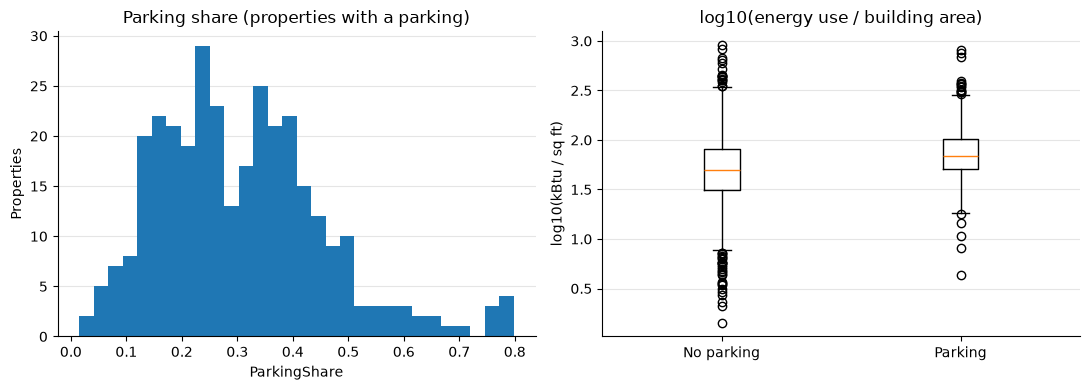

,Pearson with log intensity
HasParking (all properties),0.20
ParkingShare (all properties),0.22
ParkingShare (properties with a parking),0.30


In [3]:
target = df["SiteEnergyUse(kBtu)"]
log_intensity = np.log10(target / b)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df.loc[has_parking, "ParkingShare"], bins=30)
axes[0].set(
    title="Parking share (properties with a parking)",
    xlabel="ParkingShare",
    ylabel="Properties",
)
axes[1].boxplot(
    [log_intensity[~has_parking], log_intensity[has_parking]],
    tick_labels=["No parking", "Parking"],
)
axes[1].set(title="log10(energy use / building area)", ylabel="log10(kBtu / sq ft)")
plt.tight_layout()
plt.show()

correlations = {
    "HasParking (all properties)": has_parking.astype(int).corr(log_intensity),
    "ParkingShare (all properties)": df["ParkingShare"].corr(log_intensity),
    "ParkingShare (properties with a parking)": df.loc[
        has_parking, "ParkingShare"
    ].corr(log_intensity[has_parking]),
}
pd.Series(correlations, name="Pearson with log intensity").round(2).to_frame()

The correlations are positive but weak. At equal building area, properties with a parking use more energy. On all properties, the flag and the share carry the same signal. Among properties with a parking, the share still correlates with the EUI, so the size of the parking matters.

### Decision

We keep `ParkingShare` alone, with no `HasParking` flag. Together with the building area, it carries the same information as `PropertyGFAParking`, which we drop.

In [4]:
columns_to_drop.append("PropertyGFAParking")

## 2. Mixed usage

A property with several activities (offices and a restaurant, for example) may have a different energy profile from a single-use one.

We first look at the second use type, and at how often it is "Parking", already captured by `ParkingShare`.

Properties with a second use type: 831 / 1535 (54.1%)
Share of 'Parking' among second use types: 39.5%


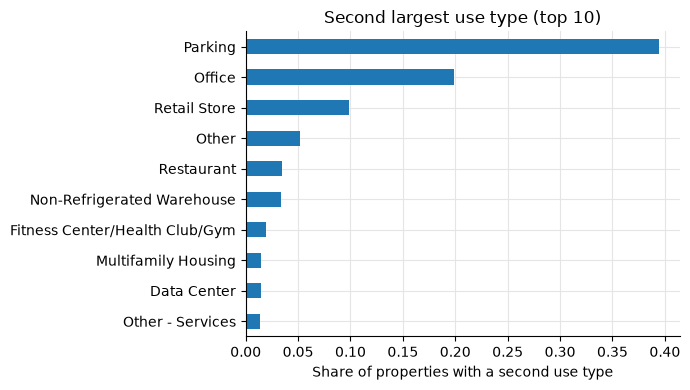

,count,share
SecondLargestPropertyUseType,,
Parking,328,0.395
Office,165,0.199
Retail Store,82,0.099
Other,43,0.052
Restaurant,29,0.035
Non-Refrigerated Warehouse,28,0.034
Fitness Center/Health Club/Gym,16,0.019
Data Center,12,0.014
Multifamily Housing,12,0.014


In [5]:
second = df["SecondLargestPropertyUseType"]
n_second = second.notna().sum()
print(
    f"Properties with a second use type: {n_second} / {len(df)} ({n_second / len(df):.1%})"
)

breakdown = second.value_counts().to_frame("count")
breakdown["share"] = breakdown["count"] / n_second
print(
    f"Share of 'Parking' among second use types: {breakdown.loc['Parking', 'share']:.1%}"
)

top = breakdown.head(10)
ax = top["share"].sort_values().plot.barh(figsize=(7, 4))
ax.set(
    title="Second largest use type (top 10)",
    xlabel="Share of properties with a second use type",
    ylabel="",
)
plt.tight_layout()
plt.show()

top.round(3)

Parking is the most frequent second use (40%). A flag based on the second use would mostly repeat the parking information. The two parking sources also disagree. We use the parking area as the reference, and exclude Parking from the mixed-usage definition.

### All declared use types

`ListOfAllPropertyUseTypes` lists every use of a property, including minor ones.

In [6]:
combinations = df["ListOfAllPropertyUseTypes"].value_counts()
print(
    f"Distinct combinations: {len(combinations)} (appearing once: {(combinations == 1).sum()})"
)
combinations.head(20).to_frame("count")

Distinct combinations: 360 (appearing once: 245)


,count
ListOfAllPropertyUseTypes,
Office,132
"Office, Parking",119
Non-Refrigerated Warehouse,100
"Non-Refrigerated Warehouse, Office",61
Other,58
Retail Store,52
K-12 School,46
Worship Facility,46
Hotel,43


### Split the list into use types

Some labels contain commas, for example `Repair Services (Vehicle, Shoe, Locksmith, etc)`. We split on the commas outside parentheses.

In [7]:
all_uses = df["ListOfAllPropertyUseTypes"]
assert all_uses.notna().all(), "NaN would be counted as a use type after explode"

# Split on commas that are not inside parentheses
use_types = all_uses.str.split(r",\s*(?![^()]*\))", regex=True).explode()

# Check: labels that never appear as largest or second largest use
reference = set(df["LargestPropertyUseType"].dropna()) | set(second.dropna())
use_types[~use_types.isin(reference)].value_counts().to_frame("properties")

,properties
ListOfAllPropertyUseTypes,
Other - Technology/Science,6
Fast Food Restaurant,2
Outpatient Rehabilitation/Physical Therapy,2
Energy/Power Station,1
Single Family Home,1
Vocat,1


Only 6 labels never appear as the largest or second use. They are minor uses or a truncated label, so the split is correct.

In [8]:
# Number of distinct use types, parking excluded
n_uses = (
    use_types[use_types != "Parking"]
    .groupby(level=0)
    .nunique()
    .reindex(df.index, fill_value=0)  # properties declaring only Parking
)
print(
    f"Properties with more than one use (parking excluded): "
    f"{(n_uses > 1).sum()} / {len(df)} ({(n_uses > 1).mean():.1%})"
)
n_uses.value_counts().sort_index().to_frame("properties")

Properties with more than one use (parking excluded): 592 / 1535 (38.6%)


,properties
ListOfAllPropertyUseTypes,
1,943
2,351
3,149
4,56
5,22
6,8
7,1
8,2
9,2


### Definition of `HasMixedUsage`

We compare two definitions:

- Variant A: the second use type exists and is not Parking. It only looks at the two largest uses.
- Variant B: at least two distinct uses other than Parking in `ListOfAllPropertyUseTypes`. It looks at all declared uses.

In [9]:
variant_a = second.notna() & (second != "Parking")
variant_b = n_uses >= 2

print(
    f"Variant A: {variant_a.sum()} ({variant_a.mean():.1%}) | Variant B: {variant_b.sum()} ({variant_b.mean():.1%})"
)
pd.crosstab(variant_a.rename("Variant A"), variant_b.rename("Variant B"), margins=True)

Variant A: 503 (32.8%) | Variant B: 592 (38.6%)


Variant B,False,True,All
Variant A,,,
False,931,101,1032
True,12,491,503
All,943,592,1535


The variants disagree on 113 properties. In 101 of them, Parking is the second use, so variant A misses the real second activity (for example `Hotel, Parking, Restaurant`). Most of the 12 others are parking garages with one other activity, which variant B treats as single-use.

### Decision

We keep variant B. It does not depend on the rank of Parking and it uses all the declared uses. Both groups are large enough to be learned (592 mixed, 943 single-use).

In [10]:
use_columns = [
    "LargestPropertyUseType",
    "SecondLargestPropertyUseType",
    "ListOfAllPropertyUseTypes",
]
columns_to_drop.extend(use_columns)
df["HasMixedUsage"] = variant_b.astype(int)
(
    log_intensity.groupby(df["HasMixedUsage"])
    .agg(properties="count", median_intensity=lambda s: 10 ** s.median())
    .rename(index={0: "Single use", 1: "Mixed use"})
    .round(1)
)

,properties,median_intensity
HasMixedUsage,,
Single use,943,53.0
Mixed use,592,53.9


The median EUI is almost the same for mixed and single-use properties. The flag alone does not shift the EUI. It may still help in combination with the property type: the modeling will tell.

## 3. Construction period

We group the construction year into periods bounded by the successive Washington State energy codes. A building is designed under the code in force when it was built.

- 1977: first State Energy Code
- 1991: Nonresidential Energy Code Act
- 2009: the State Energy Code is aligned with the international code (IECC)

*Source: [Washington State Building Code Council History](https://sbcc.wa.gov/about-sbcc/history)*

In [11]:
period_labels = ["Before 1977", "1977-1990", "1991-2008", "2009+"]

period = pd.cut(
    df["YearBuilt"],
    bins=[-np.inf, 1976, 1990, 2008, np.inf],
    labels=period_labels,
).rename("ConstructionPeriod")

by_period = (
    period.value_counts()
    .sort_index()
    .rename_axis("ConstructionPeriod")
    .to_frame("properties")
)
by_period["share"] = (by_period["properties"] / len(df)).round(3)
by_period

,properties,share
ConstructionPeriod,,
Before 1977,953,0.621
1977-1990,233,0.152
1991-2008,271,0.177
2009+,78,0.051


### Splitting the first period at 1946

"Before 1977" holds about two thirds of the properties. We split it at the end of the Second World War to check whether the two halves differ.

In [12]:
period_labels = ["Before 1946", "1946-1976", "1977-1990", "1991-2008", "2009+"]
period = pd.cut(
    df["YearBuilt"],
    bins=[-np.inf, 1945, 1976, 1990, 2008, np.inf],
    labels=period_labels,
).rename("ConstructionPeriod")

intensity = df["SiteEnergyUse(kBtu)"] / df["PropertyGFABuilding(s)"]
(intensity.groupby(period).agg(properties="count", median_intensity="median").round(1))

,properties,median_intensity
ConstructionPeriod,,
Before 1946,453,46.2
1946-1976,500,52.5
1977-1990,233,55.1
1991-2008,271,72.9
2009+,78,45.9


The median EUI is about 13% higher after 1946 than before. This matches a change in building practices: thick masonry and little air conditioning before 1946, glass curtain walls and widespread air conditioning after.

The median EUI rises with the period up to 1991-2008, then falls for 2009+. The relationship is not monotonic.

### Decision

We keep the five periods, and they replace `YearBuilt`. A linear model on the year would only capture a slope.

One caveat: older buildings may have been retrofitted. The period describes the original construction, not the current state.

In [13]:
df["ConstructionPeriod"] = period
columns_to_drop.append("YearBuilt")

## 4. Floor area per floor

At equal floor area, a low, wide building (a warehouse) does not behave like a tower. The expected effect works both ways. A wide building has less facade per sq ft, so less heat loss. But its central areas are far from windows, so they need more lighting and ventilation.

In [14]:
floors = df["NumberofFloors"]

print(f"dtype: {floors.dtype}")
print(f"Missing (NaN): {floors.isna().sum()}")
print(f"Zero floors:   {(floors == 0).sum()}")
print(f"Negative:      {(floors < 0).sum()}")
print(f"Non-integer:   {(floors.dropna() % 1 != 0).sum()}")

# Check: dividing by 0 would give inf without any error
assert not np.isinf(b / floors).any(), "Floors equal to 0 produce inf"

dtype: float64
Missing (NaN): 15
Zero floors:   0
Negative:      0
Non-integer:   0


No property has 0 floors any more (notebook 01 turned them into missing values). The 15 properties with a missing floor count get a missing value for the feature.

### Campuses: `NumberofBuildings > 1`

In [15]:
is_campus = df["NumberofBuildings"] > 1
print(
    f"Properties with NumberofBuildings > 1: {is_campus.sum()} / {len(df)} ({is_campus.mean():.1%})"
)
print(f"Of which with a missing floor count: {(is_campus & floors.isna()).sum()}")

print("\nNumber of floors and area per 'floor':")
pd.DataFrame(
    {
        "NumberofFloors (campus)": floors[is_campus].describe(),
        "NumberofFloors (single)": floors[~is_campus].describe(),
        "Area per floor (campus)": (b / floors)[is_campus].describe(),
        "Area per floor (single)": (b / floors)[~is_campus].describe(),
    }
).round(0)

Properties with NumberofBuildings > 1: 51 / 1535 (3.3%)
Of which with a missing floor count: 2

Number of floors and area per 'floor':


,NumberofFloors (campus),NumberofFloors (single),Area per floor (campus),Area per floor (single)
count,49.0,1471.0,49.0,1471.0
mean,3.0,4.0,82087.0,28730.0
std,3.0,6.0,93322.0,35047.0
min,1.0,1.0,5589.0,3231.0
25%,1.0,1.0,23166.0,11890.0
50%,2.0,2.0,55722.0,20218.0
75%,3.0,4.0,87900.0,31221.0
max,14.0,76.0,415632.0,530039.0


51 properties (3%) have several buildings. For them, `NumberofFloors` is a single number for several buildings. Dividing the total area of up to 27 buildings by 1 or 2 floors gives a meaningless "area per floor".

We set the feature to a missing value for these campuses. With the 15 missing floor counts, 64 properties have no value. They will be imputed inside the cross-validation, at the modeling stage.

### Extreme values

In [16]:
area_per_floor = b / floors
columns = [
    "PrimaryPropertyType",
    "NumberofBuildings",
    "NumberofFloors",
    "PropertyGFABuilding(s)",
]
extremes = (
    df[columns]
    .assign(AreaPerFloor=area_per_floor.round(0))
    .dropna(subset=["AreaPerFloor"])
)

print(f"Floors:         min {floors.min():.0f}, max {floors.max():.0f}")
print(
    f"Area per floor: min {area_per_floor.min():,.0f}, max {area_per_floor.max():,.0f}"
)
print(f"Median {area_per_floor.median():,.0f} sq ft per floor")

print("\nLowest area per floor (many floors for little area):")
display(extremes.nsmallest(5, "AreaPerFloor"))
print("Highest area per floor (few floors for a large area):")
display(extremes.nlargest(5, "AreaPerFloor"))
print("Most floors:")
display(extremes.nlargest(5, "NumberofFloors"))

Floors:         min 1, max 76
Area per floor: min 3,231, max 530,039
Median 20,506 sq ft per floor

Lowest area per floor (many floors for little area):


,PrimaryPropertyType,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),AreaPerFloor
1431,Restaurant,1.0,13.0,42000,3231.0
676,Hotel,1.0,11.0,36240,3295.0
614,Small- and Mid-Sized Office,1.0,7.0,23622,3375.0
42,Hotel,1.0,20.0,88591,4430.0
834,Mixed Use Property,1.0,4.0,17824,4456.0


Highest area per floor (few floors for a large area):


,PrimaryPropertyType,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),AreaPerFloor
100,Retail Store,1.0,1.0,530039,530039.0
971,Hospital,8.0,1.0,415632,415632.0
541,Distribution Center,1.0,1.0,411584,411584.0
124,Other,1.0,3.0,1172127,390709.0
62,Other,1.0,1.0,389000,389000.0


Most floors:


,PrimaryPropertyType,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),AreaPerFloor
498,Large Office,1.0,76.0,1632820,21484.0
182,Large Office,1.0,63.0,1195387,18974.0
240,Large Office,1.0,56.0,1215718,21709.0
220,Large Office,1.0,55.0,1115000,20273.0
178,Large Office,1.0,49.0,754455,15397.0


Nothing is removed at this stage. The tallest buildings are large offices with a consistent area per floor. The smallest areas per floor are unusual but not impossible. The widest are distribution centers, a retail store and a stadium (Safeco Field), all plausible.

The distribution is skewed to the right, but we keep the extreme values.

In [17]:
is_campus = df["NumberofBuildings"] > 1

# Floor area per floor: NaN when the floor count is missing or ambiguous (campus)
df["FloorAreaPerFloor"] = (b / floors).where(~is_campus)

print(f"Rows with a value: {df['FloorAreaPerFloor'].notna().sum()} / {len(df)}")
print(f"Rows set to NaN:   {df['FloorAreaPerFloor'].isna().sum()}")
df["FloorAreaPerFloor"].describe().round(0).to_frame()

Rows with a value: 1471 / 1535
Rows set to NaN:   64


,FloorAreaPerFloor
count,1471.0
mean,28730.0
std,35047.0
min,3231.0
25%,11890.0
50%,20218.0
75%,31221.0
max,530039.0


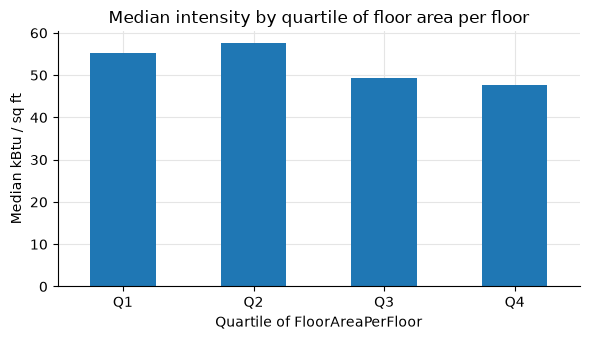

,properties,median_intensity,area_per_floor_range
FloorAreaPerFloor,,,
Q1,368,55.2,"3,231 - 11,868"
Q2,368,57.5,"11,912 - 20,218"
Q3,367,49.3,"20,233 - 31,110"
Q4,368,47.7,"31,332 - 530,039"


In [18]:
quartile = pd.qcut(df["FloorAreaPerFloor"], 4, labels=["Q1", "Q2", "Q3", "Q4"])

by_quartile = (
    intensity.groupby(quartile)
    .agg(properties="count", median_intensity="median")
    .round(1)
)
by_quartile["area_per_floor_range"] = (
    df["FloorAreaPerFloor"]
    .groupby(quartile)
    .agg(lambda s: f"{s.min():,.0f} - {s.max():,.0f}")
)

ax = by_quartile["median_intensity"].plot.bar(rot=0, figsize=(6, 3.5))
ax.set(
    title="Median intensity by quartile of floor area per floor",
    xlabel="Quartile of FloorAreaPerFloor",
    ylabel="Median kBtu / sq ft",
)
plt.tight_layout()
plt.show()

by_quartile

The relationship is weak. The EUI is roughly flat for the two narrowest quartiles, then about 15% lower for the widest ones. The differences are small compared to the spread within each quartile. The drop at the wide end may partly reflect the use: warehouses are frequent among the widest floors.

### Decision

We keep `FloorAreaPerFloor`. Its relationship with the EUI is not a straight line, which tree-based models can use.

## 5. Summary

We created four features from the existing columns: `ParkingShare`, `HasMixedUsage`, `ConstructionPeriod` and `FloorAreaPerFloor`. Each one comes from a business hypothesis. On its own, each has a weak link with the EUI. The modeling will tell whether they help.

The table gives the state of every column at the end of this notebook. *Kept*: already there and used as is. *New*: created in this notebook. *Removed*: not passed to the models.

| Column | Type | Status | Notes |
|---|---|---|---|
| `SiteEnergyUse(kBtu)` | float64 | Kept | Target. Right-skewed: modeled as log10 (notebook 01), with the predictions converted back to kBtu. |
| `PropertyGFABuilding(s)` | int64 | Kept | Size variable, parking excluded. Right-skewed: a linear model may need its log. |
| `PrimaryPropertyType` | str | Kept | Categorical, needs encoding. Carries the main use of the property (notebook 01). |
| `Neighborhood` | str | Kept | Categorical, needs encoding. |
| `Latitude` | float64 | Kept | Location. Numeric, no encoding. |
| `Longitude` | float64 | Kept | Location. Numeric, no encoding. |
| `NumberofFloors` | float64 | Kept | Missing for a few properties, to be imputed inside the cross-validation. |
| `NumberofBuildings` | float64 | Kept | Campus vs single building. |
| `ParkingShare` | float64 | New | Parking area as a share of the total area. 0 when there is no parking (a real value, not a missing one). |
| `HasMixedUsage` | int64 | New | Binary flag (0/1): at least two distinct uses other than parking. No encoding needed. |
| `ConstructionPeriod` | category | New | Five periods based on the energy codes. Categorical, needs encoding: the effect is not monotonic. |
| `FloorAreaPerFloor` | float64 | New | Building area divided by the number of floors. Missing for campuses and for properties without a floor count, to be imputed inside the cross-validation. |
| `PropertyGFAParking` | int64 | Removed | Replaced by `ParkingShare`, which carries the same information as a proportion of the total area. |
| `YearBuilt` | int64 | Removed | Summarized by `ConstructionPeriod`, in a form that matches the business reference points (energy codes). |
| `LargestPropertyUseType` | str | Removed | Never used as a feature. The use is carried by `PrimaryPropertyType` (notebook 01), and it has too many categories for a one-hot encoding. |
| `SecondLargestPropertyUseType` | str | Removed | Only used to compare the two flag variants. What it adds is found in `HasMixedUsage`. |
| `ListOfAllPropertyUseTypes` | str | Removed | Many combinations, most of them unique. Only useful to count the distinct uses, which is done in `HasMixedUsage`. |

The comparisons with the target in this notebook use the full dataset, before the train/test split. They are descriptive: they justify creating the features, not keeping them. The modeling will evaluate them through the model comparison and the permutation importance.

In [19]:
print(f"Columns to drop: {columns_to_drop}")
df.drop(columns=columns_to_drop, inplace=True)

Columns to drop: ['PropertyGFAParking', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ListOfAllPropertyUseTypes', 'YearBuilt']


## 6. Save the dataset with the new features

We save the dataset in Parquet format, which keeps the column types. Notebook 03 loads it.

In [20]:
from pathlib import Path

PROCESSED_PATH = Path("../data/processed/buildings_feature_engineered.parquet")
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_parquet(PROCESSED_PATH)
print(f"Saved {df.shape[0]} rows x {df.shape[1]} columns to {PROCESSED_PATH}")

Saved 1535 rows x 12 columns to ../data/processed/buildings_feature_engineered.parquet
